<a href="https://colab.research.google.com/github/ernesto-miguez/Research/blob/main/Determinism%20%26%20Chaotic%20Systems/Din%C3%A1mica_y_Caos_en_Redes_Profundas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Mapeo de fases de orden y caos

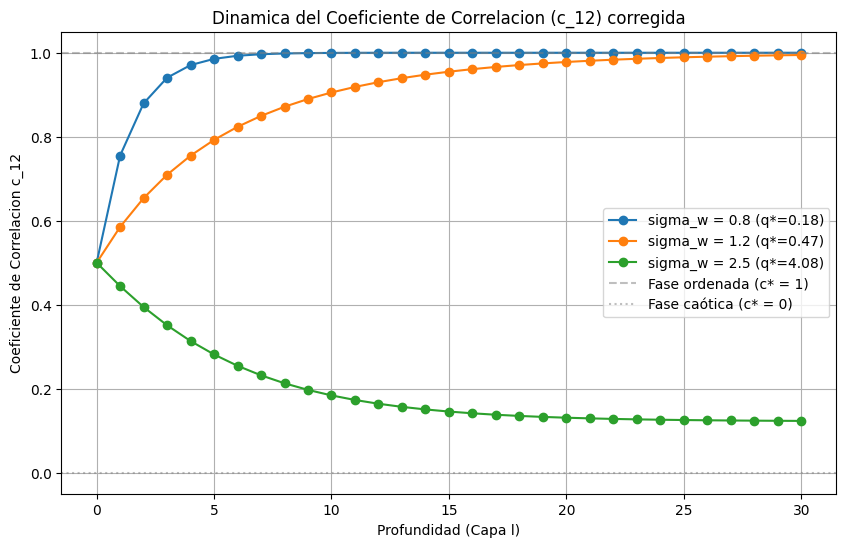

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate as integrate


def activation(u):
  return np.tanh(u)


# 1. Función para calcular el punto fijo de longitud q* (Length Map)
def compute_q_star(sigma_w, sigma_b, max_iter=100):
  q = 1.0  # Condición inicial de longitud
  for _ in range(max_iter):
    integral_val, _ = integrate.quad(
        lambda z: activation(np.sqrt(np.maximum(0.0, q)) * z) ** 2
        * np.exp(-0.5 * z ** 2)
        / np.sqrt(2 * np.pi),
        -6.0,
        6.0,
    )
    q_next = (sigma_w**2) * integral_val + sigma_b**2
    if abs(q_next - q) < 1e-6:
      return q_next
    q = q_next
  return q


# 2. Función del C-map utilizando su q* correspondiente
def compute_c_next(c_prev, q_star, sigma_w, sigma_b):
  c_prev = np.clip(c_prev, -0.9999, 0.9999)

  def integrand(z1, z2):
    u1 = np.sqrt(q_star) * z1
    u2 = np.sqrt(q_star) * (
        c_prev * z1 + np.sqrt(np.maximum(0.0, 1.0 - c_prev ** 2)) * z2
    )
    p_z = (1.0 / (2.0 * np.pi)) * np.exp(-0.5 * (z1**2 + z2**2))
    return activation(u1) * activation(u2) * p_z

  limit = 6.0
  integral_val, _ = integrate.dblquad(
      lambda z2, z1: integrand(z1, z2),
      -limit,
      limit,
      lambda z1: -limit,
      lambda z1: limit,
  )

  q_next_12 = (sigma_w**2) * integral_val + sigma_b**2
  return q_next_12


# --- SCRIPT DE SIMULACIÓN CORREGIDO Y VALIDADO ---
if __name__ == "__main__":
  sigma_b = 0.3
  layers = 30
  sigma_w_values = [0.8, 1.2, 2.5]  # Ordenado, Crítico, Caótico

  plt.figure(figsize=(10, 6))
  c_initial = 0.5

  for sw in sigma_w_values:
    # Calculamos el q* real y dinámico para este sigma_w específico
    q_star = compute_q_star(sw, sigma_b)

    c_trajectory = [c_initial]
    c_curr = c_initial
    for _ in range(layers):
      q_12_next = compute_c_next(c_curr, q_star, sw, sigma_b)
      c_curr = q_12_next / q_star
      c_curr = np.clip(c_curr, 0.0, 1.0)
      c_trajectory.append(c_curr)

    plt.plot(
        range(layers + 1),
        c_trajectory,
        marker="o",
        label=f"sigma_w = {sw} (q*={q_star:.2f})",
    )

  plt.axhline(1.0, color="gray", linestyle="--", alpha=0.5, label="Fase ordenada (c* = 1)")
  plt.axhline(0.0, color="gray", linestyle=":", alpha=0.5, label="Fase caótica (c* = 0)")
  plt.title("Dinamica del Coeficiente de Correlacion (c_12) corregida")
  plt.xlabel("Profundidad (Capa l)")
  plt.ylabel("Coeficiente de Correlacion c_12")
  plt.ylim(-0.05, 1.05)
  plt.legend()
  plt.grid(True)
  plt.show()